---
# Gresho-Chan Vortex
## Post-processing: plot and analyze the results
----

In [1]:
import glob, os
import meshio

import numpy as np
import math

import matplotlib.pyplot as plt
from matplotlib import mathtext
from scipy import stats
from tkinter import Tcl


In [2]:
# Plot parameters
params = {
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "font.size": 12,
    "legend.fontsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "text.usetex": False,
    "figure.figsize": (9, 6.45),
    "figure.subplot.left": 0.045,
    "figure.subplot.right": 0.99,
    "figure.subplot.bottom": 0.05,
    "figure.subplot.top": 0.99,
    "figure.subplot.wspace": 0.15,
    "figure.subplot.hspace": 0.12,
    "lines.markersize": 6,
    "lines.linewidth": 3.0,
}
plt.rcParams.update(params)
plt.rc('font', family='serif')
#plt.rc('text', usetex=False)

## Read simulation data

In [3]:
# Import snapshots
snapshot_number = 0
snapshot_dir = ''
files = glob.glob(snapshot_dir + "particles*.vtu")

# Sort the snapshots by Natural sort
files = Tcl().call('lsort', '-dict', files)

# Simulation parameters -- check these match the actual simulation
time_step_sim = 1e-4
snapshot_rate = 10
time = snapshot_number * snapshot_rate * time_step_sim
N_parts = 64
neighbours = 4.28
eta = 1.235
kernel = 'Cubic Spline (M4)'
scheme = 'Minimal SPH'

snapshot = files[snapshot_number]
print("============================================================")
print('Reading snapshot: ' + snapshot )
print("time of simulation = ", time)
print("============================================================")

mesh = meshio.read( snapshot )
print( 'The snapshot read contains the following data: ')
print( mesh.point_data_to_sets )
print("============================================================")

# Extract Fields
pos = mesh.point_data["x"]
x = pos[:,0] - 0.5
y = pos[:,1] - 0.5
vel = mesh.point_data["v"]
vel_x = vel[:,0] 
vel_y = vel[:,1] 
r = np.sqrt(x**2 + y**2) + 1e-10
v_phi = (-y * vel_x + x * vel_y) / r
v_norm= np.sqrt(vel_x**2 + vel_y**2)
density = mesh.point_data["density"][:,0]
pressure= mesh.point_data["pressure"][:,0]
mass    = mesh.point_data["mass"][:,0]
energy  = mesh.point_data["u"][:,0]
Omega   = mesh.point_data["Omega"][:,0]

Reading snapshot: particles-0.vtu
time of simulation =  0.0
The snapshot read contains the following data: 
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 4096
  Number of cells:
    vertex: 4096
  Point data: x, cut-off-radius, association, v, a, a_prev_step, u, mass, density, pressure, f, Omega, rho_dh, Ncount, wcount, wcount_dh, soundSpeed, timeStepSize, smoothingLength, smoothingLengthPrevious, hDot, residual, hasConverged, iterCount, hLeft, hRight, isBoundaryParticle, hasNoNeighbours, rot_v, div_v, v_sig_AV, balsara>


In [4]:
# Bin results into radial bins
rho = density
P = pressure
v = v_phi
u = energy

# Define radial bins
r_bin_edge = np.arange(0.0, 1.0, 0.02)
r_bin = 0.5 * (r_bin_edge[1:] + r_bin_edge[:-1])

# Bin the data
rho_bin, _, _  = stats.binned_statistic(r, rho    , statistic="mean", bins=r_bin_edge)
v_bin, _, _    = stats.binned_statistic(r, v      , statistic="mean", bins=r_bin_edge)
P_bin, _, _    = stats.binned_statistic(r, P      , statistic="mean", bins=r_bin_edge)
u_bin, _, _    = stats.binned_statistic(r, u      , statistic="mean", bins=r_bin_edge)
rho2_bin, _, _ = stats.binned_statistic(r, rho **2, statistic="mean", bins=r_bin_edge)
v2_bin, _, _   = stats.binned_statistic(r, v **2  , statistic="mean", bins=r_bin_edge)
P2_bin, _, _   = stats.binned_statistic(r, P **2  , statistic="mean", bins=r_bin_edge)
u2_bin, _, _   = stats.binned_statistic(r, u **2  , statistic="mean", bins=r_bin_edge)
rho_sigma_bin = np.sqrt(rho2_bin - rho_bin **2)
v_sigma_bin   = np.sqrt(v2_bin - v_bin **2)
P_sigma_bin   = np.sqrt(P2_bin - P_bin **2)
u_sigma_bin   = np.sqrt(u2_bin - u_bin **2)

/tmp/ipykernel_145830/1537483763.py:22: RuntimeWarning: invalid value encountered in sqrt
  P_sigma_bin   = np.sqrt(P2_bin - P_bin **2)
/tmp/ipykernel_145830/1537483763.py:23: RuntimeWarning: invalid value encountered in sqrt
  u_sigma_bin   = np.sqrt(u2_bin - u_bin **2)


## Analytical solution

Taken from `swiftsim/examples/HydroTests/Gresho_Vortex_2D`

In [5]:
# Parameters
rho0 = 1.0                     # Background Density
P0 = 0.0                       # Background Pressure
gas_gamma = 5.0/3.0            # Gas polytropic index

# Generate the analytic solution at this time
N = 200
R_max = 0.6

solution_r = np.arange(0, R_max, R_max / N)
solution_P = np.zeros(N)
solution_v_phi = np.zeros(N)
solution_v_r = np.zeros(N)

for i in range(N):
    if solution_r[i] < 0.2:
        solution_P[i] = P0 + 5.0 + 12.5 * solution_r[i] ** 2
        solution_v_phi[i] = 5.0 * solution_r[i]
    elif solution_r[i] < 0.4:
        solution_P[i] = (
            P0
            + 9.0
            + 12.5 * solution_r[i] ** 2
            - 20.0 * solution_r[i]
            + 4.0 * np.log(solution_r[i] / 0.2)
        )
        solution_v_phi[i] = 2.0 - 5.0 * solution_r[i]
    else:
        solution_P[i] = P0 + 3.0 + 4.0 * np.log(2.0)
        solution_v_phi[i] = 0.0

solution_rho = np.ones(N) * rho0
solution_s = solution_P / solution_rho ** gas_gamma
solution_u = solution_P / ((gas_gamma - 1.0) * solution_rho)


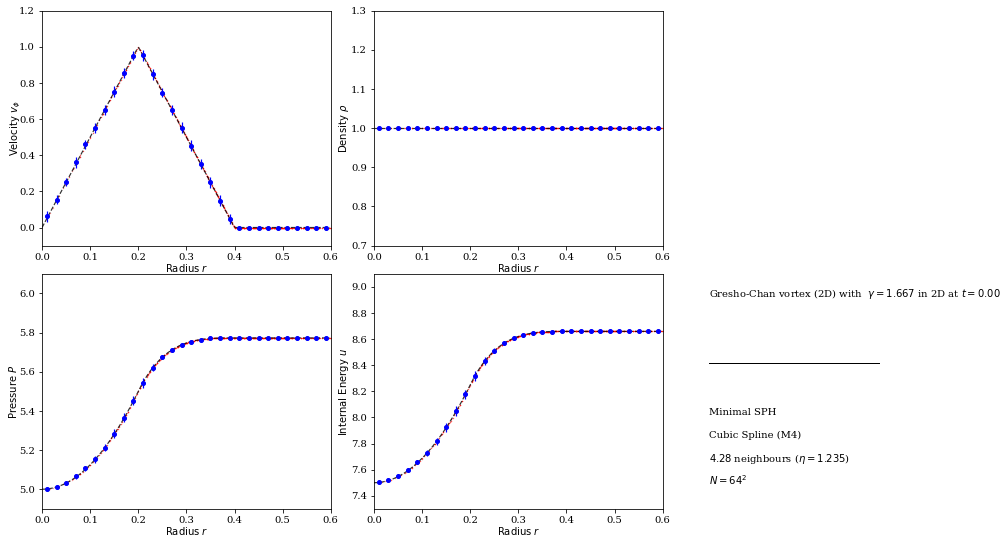

In [6]:
# Plot the interesting quantities
fig = plt.figure(figsize=(14, 8)) 

# Azhimutal velocity profile --------------------------------
plt.subplot(231)

plt.plot(r, v_phi, ".", color="r", ms=0.5, alpha=0.2)
plt.plot(solution_r, solution_v_phi, "--", color="k", alpha=0.8, lw=1.2)
plt.errorbar(r_bin, v_bin, yerr=v_sigma_bin, fmt=".", ms=8.0, color="b", lw=1.2)
plt.xlabel("${\\rm{Radius}}~r$", labelpad=0)
plt.ylabel("${\\rm{Velocity}}~v_\phi$", labelpad=-4)
plt.xlim(0, R_max)
plt.ylim(-0.1, 1.2)

# Radial density profile --------------------------------
plt.subplot(232)

plt.plot(r, rho, ".", color="r", ms=0.5, alpha=0.2)
plt.plot(solution_r, solution_rho, "--", color="k", alpha=0.8, lw=1.2)
plt.errorbar(r_bin, rho_bin, yerr=rho_sigma_bin, fmt=".", ms=8.0, color="b", lw=1.2)
plt.xlabel("${\\rm{Radius}}~r$", labelpad=0)
plt.ylabel("${\\rm{Density}}~\\rho$", labelpad=0)
plt.xlim(0, R_max)
plt.ylim(rho0 - 0.3, rho0 + 0.3)

# Radial pressure profile --------------------------------
plt.subplot(234)

plt.plot(r, P, ".", color="r", ms=0.5, alpha=0.2)
plt.plot(solution_r, solution_P, "--", color="k", alpha=0.8, lw=1.2)
plt.errorbar(r_bin, P_bin, yerr=P_sigma_bin, fmt=".", ms=8.0, color="b", lw=1.2)
plt.xlabel("${\\rm{Radius}}~r$", labelpad=0)
plt.ylabel("${\\rm{Pressure}}~P$", labelpad=0)
plt.xlim(0, R_max)
plt.ylim(4.9 + P0, P0 + 6.1)

# Radial internal energy profile -------------------------
plt.subplot(235)
plt.plot(r, u, ".", color="r", ms=0.5, alpha=0.2)
plt.plot(solution_r, solution_u, "--", color="k", alpha=0.8, lw=1.2)
plt.errorbar(r_bin, u_bin, yerr=u_sigma_bin, fmt=".", ms=8.0, color="b", lw=1.2)
plt.xlabel("${\\rm{Radius}}~r$", labelpad=0)
plt.ylabel("${\\rm{Internal~Energy}}~u$", labelpad=0)
plt.xlim(0, R_max)
plt.ylim(7.3, 9.1)

# Information -------------------------------------
plt.subplot(236, frameon=False)

plt.text(
    -0.49,
    0.9,
    "Gresho-Chan vortex (2D) with  $\\gamma=%.3f$ in 2D at $t=%.2f$" % (gas_gamma, time),
    fontsize=10,
)

plt.plot([-0.49, 0.1], [0.62, 0.62], "k-", lw=1)
#plt.text(-0.49, 0.5, "$\\textsc{Peano}$ %s" % git, fontsize=10)
plt.text(-0.49, 0.4, scheme, fontsize=10)
plt.text(-0.49, 0.3, kernel, fontsize=10)
plt.text(-0.49, 0.2, "$%.2f$ neighbours ($\\eta=%.3f$)" % (neighbours, eta), fontsize=10)
plt.text(-0.49, 0.1, "$N=%.0i^2$" % (N_parts), fontsize=10)
plt.xlim(-0.5, 0.5)
plt.ylim(0, 1)
plt.xticks([])
plt.yticks([])

plt.show()
#fig.savefig("GreshoVortex2D.png")
plt.close()